Task1

In [1]:
import re
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

Пристрій: cpu


In [2]:
pairs = [
    ("How do I change my email?", "You can update it in your profile settings."),
    ("How can I reset my password?", "You can reset your password in settings."),
    ("I forgot my password", "Click forgot password on the login page to reset it."),
    ("My order is delayed", "Your order may take a bit longer, sorry for the delay."),
    ("Where is my order?", "You can track your order in the orders section."),
    ("How do I cancel my order?", "You can cancel your order in the orders section before it ships."),
    ("How can I get a refund?", "Please open your order and click request a refund."),
    ("How long does a refund take?", "Refunds usually take five to seven business days."),
    ("How do I contact support?", "You can contact support using the chat or by email."),
    ("What payment methods do you accept?", "We accept credit cards and bank transfers."),
    ("Can I change my delivery address?", "Yes, you can change the address before the order ships."),
    ("How do I delete my account?", "You can delete your account in the profile settings."),
    ("The app is not working", "Please restart the app and try again."),
    ("I cannot log in to my account", "Please check your email and password and try again."),
    ("How do I update my payment method?", "You can update your payment method in billing settings."),
    ("Do you ship internationally?", "Yes, we ship to many countries around the world."),
    ("How much is shipping?", "Shipping cost depends on your location and is shown at checkout."),
    ("Can I change my username?", "Yes, you can change your username in the profile settings."),
    ("How do I subscribe to the newsletter?", "You can subscribe in your account settings."),
    ("How do I unsubscribe from emails?", "Click the unsubscribe link at the bottom of any email."),
    ("My payment failed", "Please check your card details and try again."),
    ("I received a damaged item", "We are sorry, please contact support and we will send a replacement."),
    ("How do I return an item?", "You can return an item within thirty days from your orders page."),
    ("Where can I find my invoice?", "You can download your invoice from the orders section."),
    ("How do I enable two factor authentication?", "You can enable it in the security settings."),
]
print("Пар у корпусі:", len(pairs))

Пар у корпусі: 25


In [3]:
def clean(text):
    """Нижній регістр, без пунктуації та чисел."""
    text = text.lower()
    return re.sub(r"[^a-z\s]", " ", text)

def tokenize(text):
    return clean(text).split()

PAD, SOS, SEP, EOS, UNK = "<pad>", "<sos>", "<sep>", "<eos>", "<unk>"
special = [PAD, SOS, SEP, EOS, UNK]

# Послідовність: <sos> запит <sep> відповідь <eos>
sequences = [[SOS] + tokenize(q) + [SEP] + tokenize(a) + [EOS] for q, a in pairs]

# Словник token-to-index
vocab_words = sorted({t for seq in sequences for t in seq if t not in special})
itos = special + vocab_words
stoi = {t: i for i, t in enumerate(itos)}
PAD_IDX, SOS_IDX, SEP_IDX, EOS_IDX, UNK_IDX = (stoi[t] for t in special)
print("Розмір словника:", len(stoi))
print("Приклад послідовності:", sequences[0])

Розмір словника: 137
Приклад послідовності: ['<sos>', 'how', 'do', 'i', 'change', 'my', 'email', '<sep>', 'you', 'can', 'update', 'it', 'in', 'your', 'profile', 'settings', '<eos>']


In [4]:
MAX_LEN = max(len(s) for s in sequences)
print("MAX_LEN:", MAX_LEN)

def encode(tokens):
    return [stoi.get(t, UNK_IDX) for t in tokens]

def pad(ids, max_len=MAX_LEN):
    return ids + [PAD_IDX] * (max_len - len(ids))

data = torch.tensor([pad(encode(s)) for s in sequences])   # (25, MAX_LEN)

# Вхід = всі токени крім останнього, ціль = зсув на 1 токен вперед
X, Y = data[:, :-1], data[:, 1:]
loader = DataLoader(TensorDataset(X, Y), batch_size=1, shuffle=True)
print("X:", X.shape, "Y:", Y.shape)

MAX_LEN: 21
X: torch.Size([25, 20]) Y: torch.Size([25, 20])


Task 2

In [5]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_size=128, num_layers=1, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        emb = self.embedding(x)                 # (B, T, E)
        out, hidden = self.lstm(emb, hidden)    # (B, T, H)
        return self.fc(out), hidden             # (B, T, V)

model = LSTMLanguageModel(len(stoi), pad_idx=PAD_IDX).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)

LSTMLanguageModel(
  (embedding): Embedding(137, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=137, bias=True)
)


In [6]:
EPOCHS = 15
losses = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits, _ = model(xb)
        loss = criterion(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        loss.backward()
        optimizer.step()
        total += loss.item()
    avg = total / len(loader)
    losses.append(avg)
    print(f"Епоха {epoch:2d}/{EPOCHS}  loss = {avg:.4f}")

Епоха  1/15  loss = 4.8641
Епоха  2/15  loss = 4.4697
Епоха  3/15  loss = 3.8075
Епоха  4/15  loss = 3.2850
Епоха  5/15  loss = 2.9036
Епоха  6/15  loss = 2.6270
Епоха  7/15  loss = 2.3468
Епоха  8/15  loss = 2.1000
Епоха  9/15  loss = 1.8736
Епоха 10/15  loss = 1.6675
Епоха 11/15  loss = 1.4793
Епоха 12/15  loss = 1.3001
Епоха 13/15  loss = 1.1619
Епоха 14/15  loss = 1.0388
Епоха 15/15  loss = 0.9277


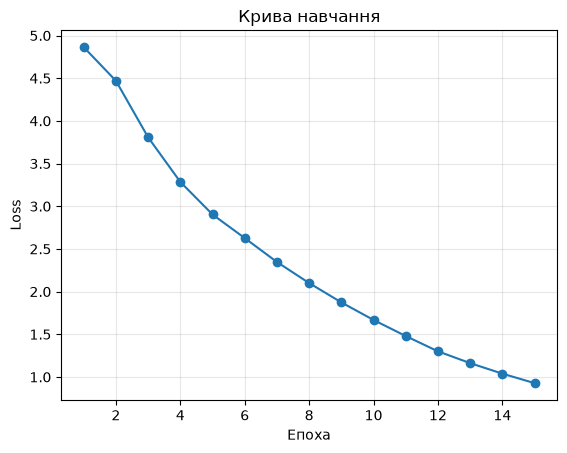

In [8]:
import matplotlib.pyplot as plt
plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("Епоха"); plt.ylabel("Loss"); plt.title("Крива навчання"); plt.grid(alpha=0.3)
plt.show()

Task 3

In [9]:
@torch.no_grad()
def generate(question, max_new_tokens=15):
    model.eval()
    ids = encode([SOS] + tokenize(question) + [SEP])
    x = torch.tensor([ids], device=device)
    logits, hidden = model(x)
    out = []
    for _ in range(max_new_tokens):
        next_id = logits[0, -1].argmax().item()
        if next_id == EOS_IDX:
            break
        out.append(itos[next_id])
        logits, hidden = model(torch.tensor([[next_id]], device=device), hidden)
    return " ".join(out)

test_queries = [
    "How can I reset my password?",
    "My order is delayed",
    "How do I change my email?",
    "How do I cancel my order?",
    "Where can I find my invoice?",
]
results = [(q, generate(q)) for q in test_queries]
for q, a in results:
    print(f"Запит:   {q}\nВідповідь: {a}\n")

Запит:   How can I reset my password?
Відповідь: you can update your password in settings

Запит:   My order is delayed
Відповідь: your order may take a bit longer sorry for the delay

Запит:   How do I change my email?
Відповідь: you can update your payment method in settings

Запит:   How do I cancel my order?
Відповідь: you can update your order in the orders section

Запит:   Where can I find my invoice?
Відповідь: you can update your order in the orders section



In [10]:
def stats(q, a):
    qa, aw = set(tokenize(q)), a.split()
    overlap = len(qa & set(aw))
    return len(aw), overlap

eval_df = pd.DataFrame(
    [(q, a, *stats(q, a)) for q, a in results],
    columns=["Запит", "Відповідь моделі", "Довжина (слів)", "Спільних слів із запитом"],
)
eval_df

,Запит,Відповідь моделі,Довжина (слів),Спільних слів із запитом
0,How can I reset my password?,you can update your password in settings,7,2
1,My order is delayed,your order may take a bit longer sorry for the...,11,1
2,How do I change my email?,you can update your payment method in settings,8,0
3,How do I cancel my order?,you can update your order in the orders section,9,1
4,Where can I find my invoice?,you can update your order in the orders section,9,1


In [11]:
observations = pd.DataFrame({
    "Запит": test_queries,
    "Відповідь моделі": [a for _, a in results],
    "Коментар": [
        "Логічно й по темі, але «update» замість «reset»",
        "Коректна відповідь (дослівно з навчального корпусу)",
        "Не по темі: йдеться про платіжний метод, а не про email",
        "Частково по темі (замовлення), але «update» замість «cancel»",
        "Не по темі: шаблонна відповідь про замовлення замість рахунку-фактури",
    ],
})
observations

,Запит,Відповідь моделі,Коментар
0,How can I reset my password?,you can update your password in settings,"Логічно й по темі, але «update» замість «reset»"
1,My order is delayed,your order may take a bit longer sorry for the...,Коректна відповідь (дослівно з навчального кор...
2,How do I change my email?,you can update your payment method in settings,"Не по темі: йдеться про платіжний метод, а не ..."
3,How do I cancel my order?,you can update your order in the orders section,"Частково по темі (замовлення), але «update» за..."
4,Where can I find my invoice?,you can update your order in the orders section,Не по темі: шаблонна відповідь про замовлення ...
